In [212]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score

sns.set_theme()
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00" 
RANDOM_STATE = 42
FIGSIZE = (10, 6)
TARGET = 'repeat_purchase_90d'
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / 'data'

In [36]:
train_raw = pd.read_csv(DATA / "train.csv", index_col = "ID")
test_raw = pd.read_csv(DATA / "test.csv", index_col = "ID")
clientes_raw = pd.read_csv(DATA / "clientes.csv", index_col = "customer_id")


In [37]:
datasets = {"train_raw": train_raw, 
            "test_raw": test_raw, 
            "clientes_raw": clientes_raw}

for name, dataset in datasets.items():
    print(f"dataset: {name}\nrows: {dataset.shape[0]}\ncolumns: {dataset.shape[1]}\n")
    

dataset: train_raw
rows: 6534
columns: 38

dataset: test_raw
rows: 986
columns: 37

dataset: clientes_raw
rows: 1143
columns: 12



In [38]:
train_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,0.930000,188.920000,476.740000,1087.670000,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,0.830000,175.740000,445.740000,1036.700000,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,0.760000,154.380000,389.910000,903.370000,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000,29.930000,79.740000,184.840000,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000,0.000000,0.000000,0.000000,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000,0.000000,0.000000,0.000000,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000,0.000000,13.130000,92.280000,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000,49.050000,152.540000,396.061499,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000,4.000000,11.000000,29.000000,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000,1.000000,1.000000,1.000000,5.000000e+00


In [39]:
train_raw.T

ID,10000000,10000001,10000002,10000003,10000004,10000005,10000007,10000009,10000011,10000012,...,10007664,10007665,10007666,10007667,10007669,10007670,10007671,10007672,10007673,10007674
Total a Pagar,558.11,978.8,10.33,856.83,1616.1,640.78,122.83,1409.75,962.63,457.95,...,34.65,790.78,1488.1,1456.39,81.87,3023.34,1362.26,4396.55,452.07,951.71
Total Bruto,510.9,830.02,12.0,696.61,1488.85,568.24,105.55,1272.44,786.27,372.32,...,49.5,642.91,1864.26,1195.39,66.56,3761.38,1723.1,3574.43,483.6,982.0
Total Liquido,453.75,795.77,8.4,696.61,1313.9,520.96,100.43,1146.14,782.63,372.32,...,34.65,642.91,1209.84,1184.06,66.56,2458.0,1107.53,3574.43,367.54,773.75
Total Imp_,104.36,183.03,1.93,160.22,302.2,119.82,22.4,263.61,180.0,85.63,...,0.0,147.87,278.26,272.33,15.31,565.34,254.73,822.12,84.53,177.96
Total Portes,0.0,0.0,0.0,0.0,0.0,0.0,3.05,0.0,0.0,0.0,...,0.0,0.0,9.65,0.0,3.36,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,34.25,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95,47.28,5.12,126.3,3.64,0.0,...,14.85,0.0,654.42,11.33,0.0,1303.38,581.32,0.0,116.06,208.25
Custo,153.099911,472.943134,6.097485,408.167275,485.401864,336.60065,0.0,246.974108,496.926279,129.982522,...,0.0,385.608527,429.921971,661.260577,37.15,1099.19,197.514,2075.838024,265.159468,224.543079
N_ Detalhes,4.0,32.0,1.0,9.0,33.0,11.0,5.0,66.0,46.0,14.0,...,1.0,17.0,75.0,31.0,3.0,49.0,16.0,78.0,7.0,30.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [32]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

In [40]:
train_raw.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

In [41]:
train_raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


In [46]:
train_raw.describe(include="str").T

,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738
purchase_date,6469,1492,2015-10-31,52


In [54]:
# Get a look of the data

for column in train_raw.columns:
    print(f"Column: {column}\nExamples:\n {train_raw[column].head(10)}\n")

Column: Total a Pagar
Examples:
 ID
10000000     558.11
10000001     978.80
10000002      10.33
10000003     856.83
10000004    1616.10
10000005     640.78
10000007     122.83
10000009    1409.75
10000011     962.63
10000012     457.95
Name: Total a Pagar, dtype: float64

Column: Total Bruto
Examples:
 ID
10000000     510.90
10000001     830.02
10000002      12.00
10000003     696.61
10000004    1488.85
10000005     568.24
10000007     105.55
10000009    1272.44
10000011     786.27
10000012     372.32
Name: Total Bruto, dtype: float64

Column: Total Liquido
Examples:
 ID
10000000     453.75
10000001     795.77
10000002       8.40
10000003     696.61
10000004    1313.90
10000005     520.96
10000007     100.43
10000009    1146.14
10000011     782.63
10000012     372.32
Name: Total Liquido, dtype: float64

Column: Total Imp_
Examples:
 ID
10000000    104.36
10000001    183.03
10000002      1.93
10000003    160.22
10000004    302.20
10000005    119.82
10000007     22.40
10000009    263.61


### Missing Values

In [74]:
row_missing_count = train_raw.isna().sum(axis=1)
row_missing_count.value_counts()

0     3929
1     1287
7      511
3      354
2      190
4      100
8       86
36      65
5        6
9        6
Name: count, dtype: int64

In [76]:
rows_with_36_missings = train_raw[row_missing_count==36]
rows_with_36_missings

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10007151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,151492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007169,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,230585,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007339,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,902830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [79]:
# Check if the ID is duplicated
other_rows = train_raw[row_missing_count != 36]
rows_with_36_missings.index.isin(other_rows.index).sum()

np.int64(0)

In [91]:
# Check if these ID are from the same customer form another purchase
incomplete_customers = rows_with_36_missings["customer_id"]
incomplete_customers.isin(other_rows["customer_id"]).value_counts()


customer_id
True     62
False     3
Name: count, dtype: int64

In [92]:
# Check the 3 customers that we don't have in the train data to see if they exists in clientes.csv
incomplete_customers[~incomplete_customers.isin(other_rows["customer_id"])] 

ID
10001116    793048
10001537    133497
10007590    697676
Name: customer_id, dtype: int64

In [97]:
new_customers_with_no_data = [793048, 133497, 697676]

for customer in new_customers_with_no_data:
    clientes_info = clientes_raw[clientes_raw.index == customer]

    if clientes_info.empty:
        print(f"Customer {customer}: NOT FOUND")
    else:
        print(f"Customer {customer}: FOUND")
        display(clientes_info)
    

Customer 793048: FOUND


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
793048,Country CT10: Land of The Final Version,Region RG19: We Will See Later,NaN,Municipality MU42: Council of Last Minute Edits,City CY227: AutoFill Village,Postal area PA217: Hidden Sheet Sector,Postal code PC425: #REF! Delivery Route,Street ST242: PowerPoint New Parade,Address AD639: Cell Without a Home,NaN,Excel Is Not A Database Ltd 313,2015


Customer 133497: FOUND


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
133497,Country CT10: Land of The Final Version,Region RG32: We Will See Later,NaN,Municipality MU147: Council of Last Minute Edits,NaN,Postal area PA15: Hidden Sheet Sector,Postal code PC77: #REF! Delivery Route,NaN,Address AD950: Cell Without a Home,NaN,Excel Is Not A Database Ltd 435,2016


Customer 697676: FOUND


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
697676,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,Municipality MU4: Council of Last Minute Edits,NaN,Postal area PA251: Hidden Sheet Sector,Postal code PC531: #REF! Delivery Route,Street ST60: Frozen Pane Avenue,Address AD212: Cell Without a Home,NaN,Excel Is Not A Database Ltd 242,2015


Notes:
For the missing values in the general aspect of the dataframe, we have found out that in every column (except ID, cumtomer_id and repeat_purchase_90d) have missing values, at this point we are not focusing in these missings column by column, more in the big picture, because of this, at this momnet the relevant info that we have retrieved is the folling:

· 65 rows have no info except ID, cumtomer_id and repeat_purchase_90d

· From these 65, 62 are customers that are linked with one or more purchases in the train_raw

· The 3 missing, even though that we don't have any more purchase than the empty row, we have found these customers in clientes.csv

In [101]:
train_raw.duplicated().sum()

np.int64(10)

In [107]:
duplicated_rows = train_raw[train_raw.duplicated(keep=False)]
duplicated_rows.T

ID,10000457,10000560,10000983,10002381,10003209,10003718,10004187,10004463,10004649,10005141,10005177,10005269,10005608,10006618,10006879,10007583
Total a Pagar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Bruto,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Liquido,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Imp_,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Portes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Desc_ Global,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Desc_ Linha,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Custo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
N_ Detalhes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
invoice_count_current_purchase,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [111]:
# See if all these duplicated are in the list of the rows where 36 columns are NaN
duplicated_rows.index.isin(rows_with_36_missings.index).all()

np.True_

In [112]:
train_raw.index.duplicated().sum()

np.int64(0)

### Cardinality 

In [115]:
train_raw.nunique(dropna=False).sort_values()

repeat_purchase_90d                  2
warehouse                            3
document_series                      4
invoice_count_current_purchase       6
commercial_zone                      6
salesperson                         10
payment_type                        10
purchase_count_30d                  13
purchase_count_90d                  24
purchase_count_180d                 39
purchase_count_365d                 62
transport_method                    81
Total Desc_ Global                 110
N_ Detalhes                        172
Total Portes                       216
prior_purchase_count               278
days_since_previous_purchase       496
customer_id                        610
prior_max_purchase_value          1157
prior_min_purchase_value          1158
purchase_date                     1493
spend_30d                         2106
customer_tenure_days              2122
Total Desc_ Linha                 3521
spend_90d                         3524
prior_mean_gap_days      

Anomalies detected for future study:

transport_method -> Too many different categories

random_noise -> Each of the values in all records are different, the 6469 + the Nans

customer_id -> Surprisingly low number, that means that in the dataframe we have a lot of customer_id that have more than one purchase

### Numerical anomalies

In [117]:
train_raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


Anomalies detected for future study:

days_since_previous_purchase -> Have a min of -4, being days since the previous purchase doesn't make much sense being negative

prior_mean_gap_days -> Same as days_since_previous_purchase, might be an error from last field dragged

prior_mean_purchase_value -> The max and min seems very excesive 

spend_365d -> The max and min seems very excesive


In [120]:
numeric_columns = train_raw.select_dtypes(include="number").columns

(train_raw[numeric_columns] < 0).sum()

Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase        16
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value           16
prior_std_purchase_value             0
prior_min_purchase_value             0
prior_max_purchase_value             0
prior_mean_gap_days                 16
prior_std_gap_days                   0
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

In [138]:
negative_columns = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_mean_gap_days", "spend_365d"]

negative_columns_records = (train_raw[negative_columns] < 0).any(axis=1)

negative_records = train_raw[negative_columns_records]

print(len(negative_records.index))
print(negative_records)

63
          Total a Pagar  Total Bruto  Total Liquido  Total Imp_  Total Portes  \
ID                                                                              
10000018        2460.00      2000.00        2000.00      460.00           0.0   
10000300         322.65       276.70         262.32       60.33           0.0   
10000358        1814.29      1670.79        1475.03      339.26           0.0   
10000407         507.87       470.25         412.90       94.97           0.0   
10000519         221.74       180.28         180.28       41.46           0.0   
...                 ...          ...            ...         ...           ...   
10006915         804.57       664.22         654.12      150.45           0.0   
10006958         263.27       214.04         214.04       49.23           0.0   
10007015         359.04       382.85         291.90       67.14           0.0   
10007510          28.33        23.03          23.03        5.30           0.0   
10007587        3121.70  

We check the negative values, and if they are in different records or maybe there are two or more in different records, seeing that we have a total of 63 unique IDs and 63 are the rows obtained for the negative columns, and being the count of negative values of the:

days_since_previous_purchase        16

+

prior_mean_purchase_value           16

+

prior_mean_gap_days                 16

+

spend_365d                          15
---------------- ---------------------------
                63

We can confirm that all these 63 negative values are in different rows, which means that is not an error in one record that is being dragged while calculating other columns, but we will analize it better later on

### Summary of the potential issues seen

+ We have seen that we have 65 records where all of the fields (except ID, cumtomer_id and repeat_purchase_90d) are NaN
+ When ignoring the ID column, we get a total of 10 duplicated rows, those ID are inside the list of the 65 records that are all NaNs, so probably is a same customer_id with same target value, that there has been an error while registering the purchase
+ Pending analysis on the missings of different columns, pending deeper analisis
+ We haven't seen any major error in the cardinality of the fields, but need to analyze `transport method`that are many categories
+ Negative values, we have seen that 63 different records contain negative values in fields that shouldn't be negative
+ Extreme values, we have seen in the min and max of some of the fields, extreme values that differe a lor with the mean
+ We have identified columns stored as float that can be stored as int to reduce the storage weight improve computational power


## Analisis column by column
### ID


In [146]:
print(train_raw.index.unique())
print(len(train_raw))

Index([10000000, 10000001, 10000002, 10000003, 10000004, 10000005, 10000007,
       10000009, 10000011, 10000012,
       ...
       10007664, 10007665, 10007666, 10007667, 10007669, 10007670, 10007671,
       10007672, 10007673, 10007674],
      dtype='int64', name='ID', length=6534)
6534


As we expected, we have the same amount of unique values of our index, ID, as the total length of the dataframe, which supports the decision of making this field the index

### customer_id

In [155]:
customer_purchases = train_raw["customer_id"].value_counts()

print(f"Number of unique customers: {train_raw["customer_id"].nunique()}")
print(f"Purcheses per unique client: {customer_purchases.describe()}")

Number of unique customers: 610
Purcheses per unique client: count    610.000000
mean      10.711475
std       19.969320
min        1.000000
25%        1.000000
50%        4.000000
75%       12.000000
max      277.000000
Name: count, dtype: float64


In [157]:
customer_purchases.head(10)

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
239651     81
703834     80
227020     74
497930     73
488020     67
Name: count, dtype: int64

We see that in all the train data we have 610 different customer_id, meaning that from the 6534 records that we have in train, a lot of the purchesases are from the same customer. We have seen, that the mean and the median are very different, this comes because most of the records, 50% of them, have 4 or fewer purchases, but we have some clients that have registered a lot of purchases, example:

103940    277
258332    203

Which pumps a lot the mean, let's check how much of the dataset is represented by the top 10 clientes with the most purchases in the dataset

In [163]:
customer_purchases_top10 = customer_purchases.head(10).sum()

print(f"Number of purcheses from the top10 customers: {customer_purchases_top10}")
print(f"How much do they contribute to our dataset: {(customer_purchases_top10/len(train_raw) * 100).round(2)}%")


Number of purcheses from the top10 customers: 1145
How much do they contribute to our dataset: 17.52%


We see that only 10 customers represent a 17.52% of the records in the dataset, at the moment we will just flag this and later on we will decide how to deal with these customers

### purchase_date

In [180]:
print(f"Data type of purchase_date: {train_raw["purchase_date"].dtype}")
print(f"Number of NaN values: {train_raw["purchase_date"].isna().sum()}")
print(f"Number of NaN after converting from string to datetime: {pd.to_datetime(train_raw["purchase_date"], errors="coerce").isna().sum()}")
purchase_dates = pd.to_datetime(train_raw["purchase_date"], errors="coerce")
print(f"Earliest purchase in the dataset: {purchase_dates.min()}")
print(f"Last purchase in the dataset: {purchase_dates.max()}")
print(f"Difference between the first and last purchase of the dataset: {(purchase_dates.max() - purchase_dates.min())}")

Data type of purchase_date: str
Number of NaN values: 65
Number of NaN after converting from string to datetime: 65
Earliest purchase in the dataset: 2015-07-11 00:00:00
Last purchase in the dataset: 2025-02-15 00:00:00
Difference between the first and last purchase of the dataset: 3507 days 00:00:00


We have seen that all the records are good converted to datetime, the only NaNs are the ones that we already had, we also have checked the first and the last purchase registered in the dataset, that are almost 10 years apart

## Functions that’s  we will use

Before starting we will define some functions that we will be using to help discover useful information about the columns

In [359]:
def descrive_missing(column_name: str, dataframe):

    print(f"{column_name} describe:\n{dataframe[column_name].describe().round(2)}\n")

    print(f"column_name missings:\n{dataframe[column_name].isna().sum()}\n")
    
    top10 = dataframe.nlargest(10, column_name)
    print(f"{column_name} top 10 maximum:\n{top10[["customer_id", column_name]]}\n")
    
    print(f"The top 10 represent the: {((top10[column_name].sum()/ dataframe[column_name].sum()) * 100):.2f}% of the whole train data")

In [312]:
def histograms_one_column(column_name: str, dataframe, quantile: float):
    plt.hist(dataframe[column_name], bins=500)
    plt.xlabel(column_name)
    plt.ylabel("Number of purchases")
    
    plt.show()

    plt.hist(dataframe[column_name], bins=500)
    plt.xlim(0, dataframe[column_name].quantile(quantile))
    plt.xlabel(column_name)
    plt.ylabel("Number of purchases")
    
    plt.show()

In [415]:
def comparission_of_top10(columns_name: list, dataframe):
    top10s = {}
    for column in columns_name:
        top10s[column] = set(dataframe.nlargest(10, column).index)
    
    common_purchases = {}

    for column_i in columns_name:
        common_purchases[column_i] = {}
        for column_j in columns_name:
            if column_i != column_j:
                common_purchases[column_i][column_j] = len(top10s[column_i].intersection(top10s[column_j]))


    for column_i in columns_name:  
        print(f"\nColumn {column_i} have the following top10 in common with:")
        for column_j in columns_name:
            if column_i != column_j:
                print(f"     Column {column_j}: {common_purchases[column_i][column_j]}")

## Total columns

### Total Bruto

In [360]:
descrive_missing("Total Bruto", train_raw)

Total Bruto describe:
count     6469.00
mean       886.15
std       1327.64
min          0.83
25%        175.74
50%        445.74
75%       1036.70
max      21578.28
Name: Total Bruto, dtype: float64

column_name missings:
65

Total Bruto top 10 maximum:
          customer_id  Total Bruto
ID                                
10001077       227020     21578.28
10003479       227020     17644.61
10005415       755628     14570.54
10003822       227020     13443.46
10003996       807493     13371.49
10005016       807493     13008.46
10004243       781977     12937.14
10002107       400536     12500.00
10001172       531725     12260.66
10002416       531725     11249.36

The top 10 represent the: 2.49% of the whole train data


We can see that we have the usaual 6469 records, that are the length of the dataset - 65 records with NaNs, at the moment we can just flag that the maximum is very big, but seeing that the top 10 of the total brutal does not represnt a lot in the dataframe, we will do nothing at this stage, also we can see that those top 10 total bruto per purchse, some of them are from the same customers, which can gives us information on the customer behaviour

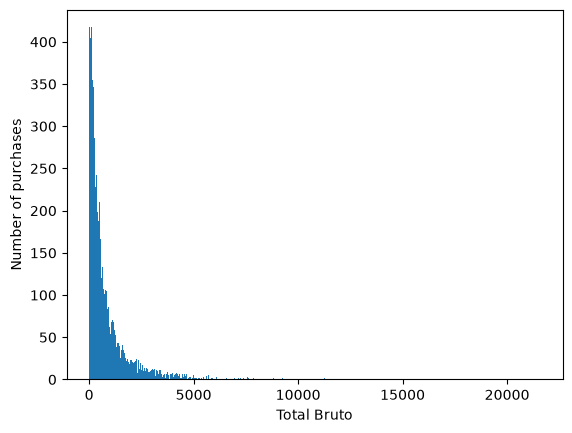

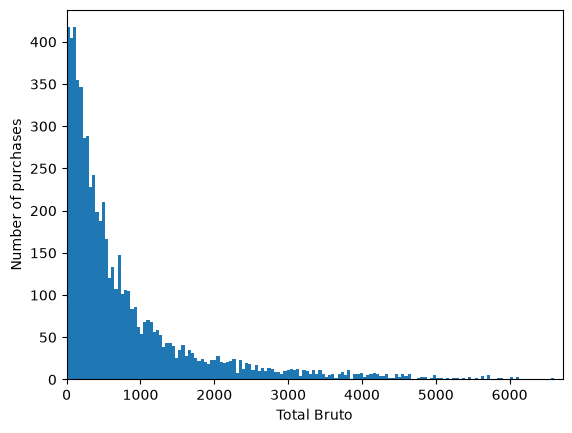

In [313]:
histograms_one_column("Total Bruto", train_raw, 0.99)

With these histograms, we can confirm what we already suspected in the describe(), why the mean and the median where so different, we see that most of the values of Total Bruto, happens in the purchases with the fewer Total Bruto, but because there are some purchases with so big Total Bruto, our mean increases a lot. Even though that we detect a great asimetry in the histogram, we will not transorm anything at the moment

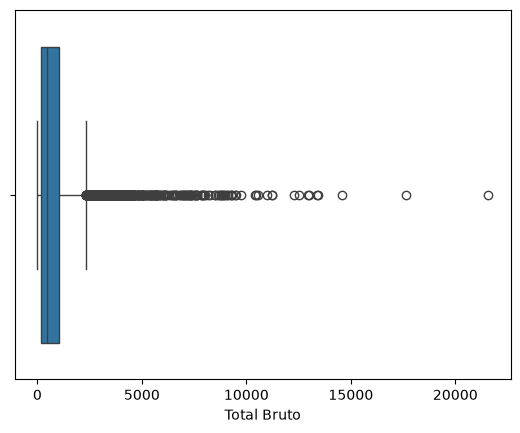

In [232]:
sns.boxplot(x=train_raw["Total Bruto"])

plt.show()

In [333]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 886.15
std = 1327.64
minimum = 0.83
q1 = 175.74
q2 = 445.74
q3 = 1036.70
maximum = 21578.28

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total Bruto"] > upper_bound]
lower_outliers = train_raw[train_raw["Total Bruto"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 2328.14
Lower bound: -1115.70
Number of upper outliers: 584
Number of lower outliers: 0
Total number of outliers: 584
Percentatge of outliers in our data: 8.94%


With this analysis we can confirm what we did know before, we have the outliers in the upper part, as the most of the records are in the lower side, we have a count of 584 outliers, taht represent a 8.94% of the data, later on we will decide how to deal with them, at the moment we just flagged it


### Total a Pagar

In [361]:
descrive_missing("Total a Pagar", train_raw)

Total a Pagar describe:
count     6469.00
mean       925.56
std       1335.00
min          0.93
25%        188.92
50%        476.74
75%       1087.67
max      22297.21
Name: Total a Pagar, dtype: float64

column_name missings:
65

Total a Pagar top 10 maximum:
          customer_id  Total a Pagar
ID                                  
10001077       227020       22297.21
10003479       227020       18146.78
10005415       755628       17257.99
10003822       227020       14433.41
10004393       588588       12961.99
10006444       864223       12905.74
10006123       227020       11461.94
10004243       781977       11457.01
10003225       755628       11250.72
10007062       942149       11031.74

The top 10 represent the: 2.39% of the whole train data


In [265]:
common_purchases = total_a_pagar_top10.index.intersection(total_bruto_top10.index)

print(f"The purchases that are present in both the top10 of total a pagar and total bruto are: {len(common_purchases)}")

print(f"They are the following: {common_purchases.tolist()}")

The purchases that are present in both the top10 of total a pagar and total bruto are: 5
They are the following: [10001077, 10003479, 10005415, 10003822, 10004243]


At the moment, we can see what we already knew, we have 65 NaNs that are from the 65 records that has no information, they just report the ID, customer_id and purchase_date, looking at the descrive, we can expect to have very similar plots from Total Bruto, as we have a much bigger mean than median, and the records will concentrate at the lower end. We also have checked if it's a similar list the top 10 of total a pagar and total bruto, and 5 of the purchases are in both of the top 10. We will not flagged any issue, as it's normal that both lists are similar, but changes can happen, as it may vary because of fields like Total Liquido, Total Imp_, Total Portes, Total Desc_ Global, Total Desc_ Linha...

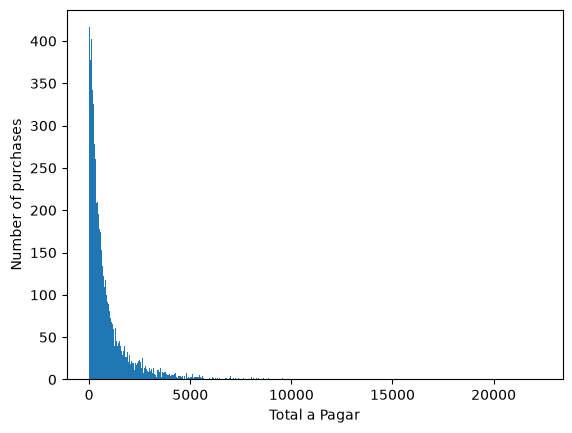

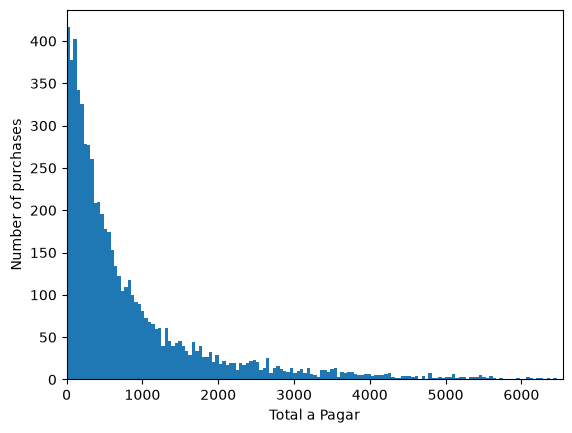

In [315]:
histograms_one_column("Total a Pagar", train_raw, 0.99)

With these histograms, we can confirm what we already suspected in the describe(), why the mean and the median where so different, we see that most of the values of Total a Pagar, happens in the purchases with the fewer Total a Pagar, but because there are some purchases with so big Total a pagar, our mean increases a lot. Even though that we detect a great asimetry in the histogram, we will not transorm anything at the moment. Follows a very similar pattern as Total Bruto

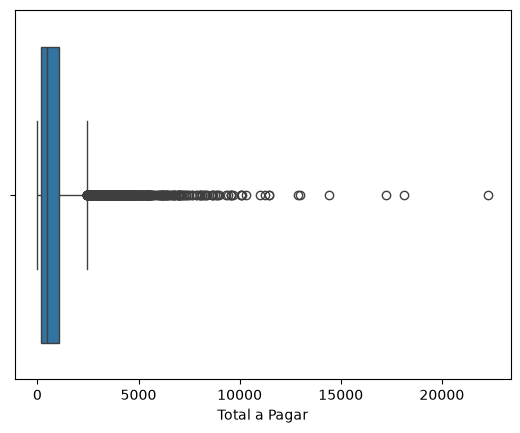

In [268]:
sns.boxplot(x=train_raw["Total a Pagar"])

plt.show()

In [334]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 925.56
std = 1335.00
minimum = 0.93
q1 = 188.92
q2 = 476.74
q3 = 1087.67
maximum = 22297.21

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total a Pagar"] > upper_bound]
lower_outliers = train_raw[train_raw["Total a Pagar"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 2435.80
Lower bound: -1159.21
Number of upper outliers: 592
Number of lower outliers: 0
Total number of outliers: 592
Percentatge of outliers in our data: 9.06%


With this analysis we can confirm what we did know before, we have the outliers in the upper part, as the most of the records are in the lower side, we have a count of 592 outliers, taht represent a 9.06% of the data, later on we will decide how to deal with them, at the moment we just flagged it

### Total Liquido

In [362]:
descrive_missing("Total Liquido", train_raw)

Total Liquido describe:
count     6469.00
mean       773.34
std       1136.36
min          0.76
25%        154.38
50%        389.91
75%        903.37
max      18127.81
Name: Total Liquido, dtype: float64

column_name missings:
65

Total Liquido top 10 maximum:
          customer_id  Total Liquido
ID                                  
10001077       227020       18127.81
10003479       227020       14753.48
10005415       755628       14030.89
10003822       227020       11734.48
10004393       588588       10538.20
10006444       864223       10492.47
10005016       807493       10082.56
10007062       942149        9762.60
10003996       807493        9576.98
10006123       227020        9318.65

The top 10 represent the: 2.37% of the whole train data


In [274]:
common_purchases = total_a_pagar_top10.index.intersection(total_liquido_top10.index)

print(f"The purchases that are present in both the top10 of total a pagar and total liquido are: {len(common_purchases)}")

print(f"They are the following: {common_purchases.tolist()}")

common_purchases = total_liquido_top10.index.intersection(total_bruto_top10.index)

print(f"The purchases that are present in both the top10 of total liquido and total bruto are: {len(common_purchases)}")

print(f"They are the following: {common_purchases.tolist()}")

The purchases that are present in both the top10 of total a pagar and total liquido are: 8
They are the following: [10001077, 10003479, 10005415, 10003822, 10004393, 10006444, 10006123, 10007062]
The purchases that are present in both the top10 of total liquido and total bruto are: 6
They are the following: [10001077, 10003479, 10005415, 10003822, 10005016, 10003996]


As we have being seeing in the other Total fields, it seems that is going to be very right skweded histogram, we see that there's a lot of difference between the mean and the median (even though it's less than the other Totals that we have being seeing). Also, we see that there are common purchases Total a Pagar and Total Bruto.

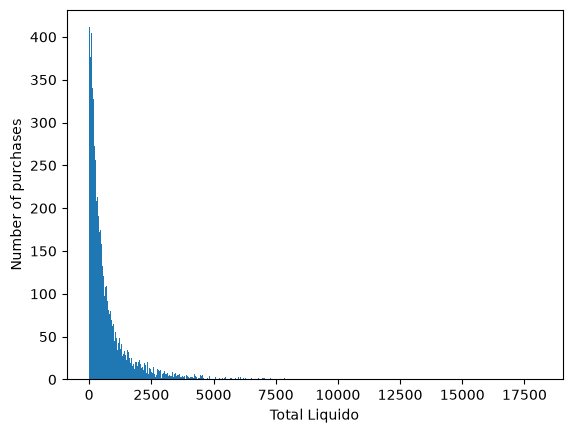

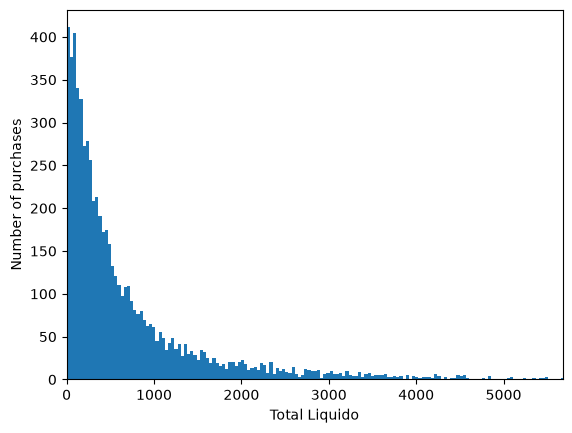

In [317]:
histograms_one_column("Total Liquido", train_raw, 0.99)

With these histograms, we can confirm what we already suspected in the describe(), why the mean and the median where so different, we see that most of the values of Total Liquido, happens in the purchases with the fewer Total Liquido, but because there are some purchases with so big Total Liquido, our mean increases a lot. Even though that we detect a great asimetry in the histogram, we will not transorm anything at the moment. Follows a very similar pattern as Total Bruto

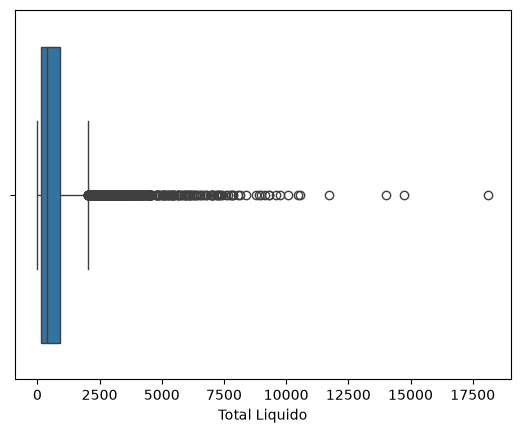

In [281]:
sns.boxplot(x=train_raw["Total Liquido"])

plt.show()

In [335]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 773.34
std = 1136.36
minimum = 0.76
q1 = 154.38
q2 = 389.91
q3 = 903.37
maximum = 18127.81

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total Liquido"] > upper_bound]
lower_outliers = train_raw[train_raw["Total Liquido"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 2026.86
Lower bound: -969.11
Number of upper outliers: 587
Number of lower outliers: 0
Total number of outliers: 587
Percentatge of outliers in our data: 8.98%


With this analysis we can confirm what we did know before, we have the outliers in the upper part, as the most of the records are in the lower side, we have a count of 587 outliers, taht represent a 8.98% of the data, later on we will decide how to deal with them, at the moment we just flagged it

### Total Imp_ 

In [363]:
descrive_missing("Total Imp_", train_raw)

Total Imp_ describe:
count    6469.00
mean      152.22
std       225.26
min         0.00
25%        29.93
50%        79.74
75%       184.84
max      4169.40
Name: Total Imp_, dtype: float64

column_name missings:
65

Total Imp_ top 10 maximum:
          customer_id  Total Imp_
ID                               
10001077       227020     4169.40
10003479       227020     3393.30
10005415       755628     3227.10
10003822       227020     2698.93
10004393       588588     2423.79
10006444       864223     2413.27
10006123       227020     2143.29
10004243       781977     2142.38
10003225       755628     2103.79
10006504       227020     1925.46

The top 10 represent the: 2.71% of the whole train data


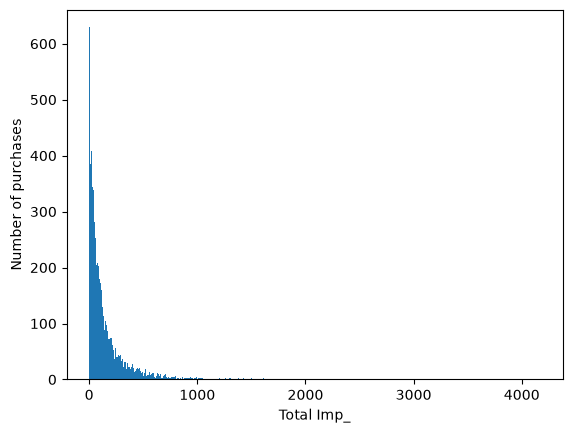

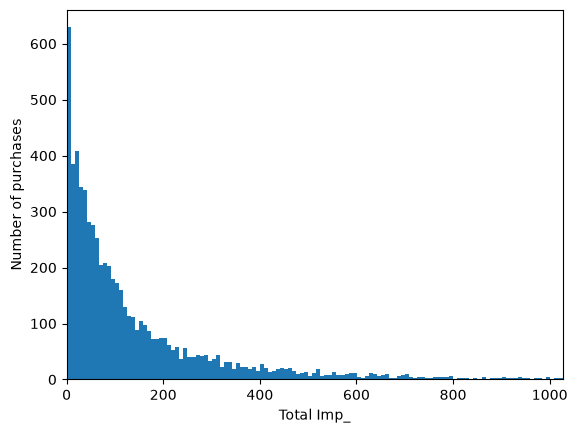

In [319]:
histograms_one_column("Total Imp_", train_raw, 0.99)

A partir de ahora no hago comparar los totales, al final, haré las comprovaciones de los top 10, para ver cuales son más comunes + pequeña explicacion


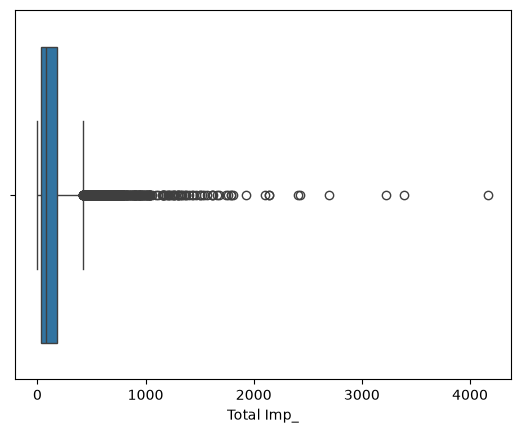

In [320]:
sns.boxplot(x=train_raw["Total Imp_"])

plt.show()

In [336]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 152.22
std = 225.26
minimum = 0.00
q1 = 29.93
q2 = 79.74
q3 = 184.84
maximum = 4169.40

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total Imp_"] > upper_bound]
lower_outliers = train_raw[train_raw["Total Imp_"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 417.21
Lower bound: -202.44
Number of upper outliers: 533
Number of lower outliers: 0
Total number of outliers: 533
Percentatge of outliers in our data: 8.16%


### Total Portes

In [364]:
descrive_missing("Total Portes", train_raw)

Total Portes describe:
count    6469.00
mean        1.15
std         5.84
min         0.00
25%         0.00
50%         0.00
75%         0.00
max       181.06
Name: Total Portes, dtype: float64

column_name missings:
65

Total Portes top 10 maximum:
          customer_id  Total Portes
ID                                 
10006514       849644        181.06
10000776       717242        159.73
10005170       630646        150.00
10005654       117553        150.00
10003236       761979        142.00
10002586       400536        140.00
10000465       816330        100.00
10002107       400536        100.00
10001065       744659         69.00
10001922       717242         65.00

The top 10 represent the: 16.87% of the whole train data


mismos mnissings, ya se puede ver en el describe que más del 75% de los registros son 0, además, viendo que el 16.87% del total de portes viene solo de 10 registros, esto también nos dice mucho

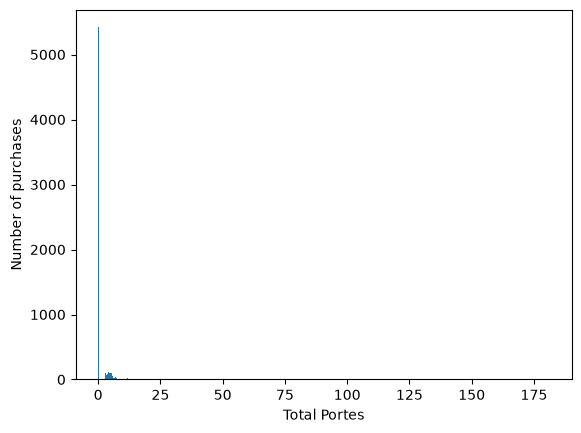

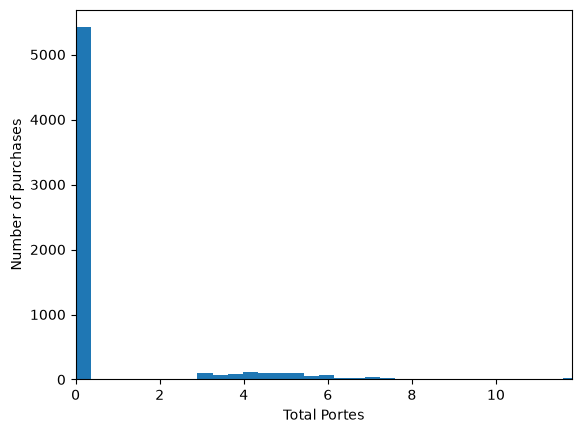

In [323]:
histograms_one_column("Total Portes", train_raw, 0.99)

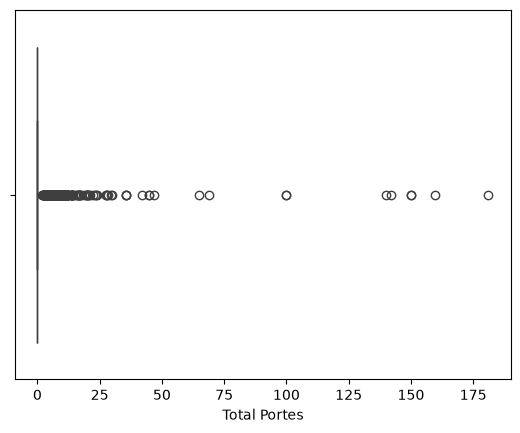

In [324]:
sns.boxplot(x=train_raw["Total Portes"])

plt.show()

In [341]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 1.15
std = 5.84
minimum = 0.00
q1 = 0.00
q2 = 0.00
q3 = 0.00
maximum = 181.06

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total Portes"] > upper_bound]
lower_outliers = train_raw[train_raw["Total Portes"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 0.00
Lower bound: 0.00
Number of upper outliers: 1053
Number of lower outliers: 0
Total number of outliers: 1053
Percentatge of outliers in our data: 16.12%


Later on we will decide what we do with this field, what we have seen here, is that most of the purchases are with 0 total portes, being every value that is no 0 an outlier

### Total Desc_ Global

In [365]:
descrive_missing("Total Desc_ Global", train_raw)

Total Desc_ Global describe:
count    6469.00
mean        0.35
std         5.12
min         0.00
25%         0.00
50%         0.00
75%         0.00
max       218.49
Name: Total Desc_ Global, dtype: float64

column_name missings:
65

Total Desc_ Global top 10 maximum:
          customer_id  Total Desc_ Global
ID                                       
10007082       113110              218.49
10004096       529466              184.40
10001765       529466              135.72
10000690       952237              115.88
10002919       473647               97.14
10005523       666120               89.62
10002808       667800               65.68
10006205       248016               57.62
10003711       847373               56.12
10007040       181764               53.84

The top 10 represent the: 47.47% of the whole train data


Más o menos lo mismo que en portes, pero hasta más, siendo el 47.47% de las compras del top 10!

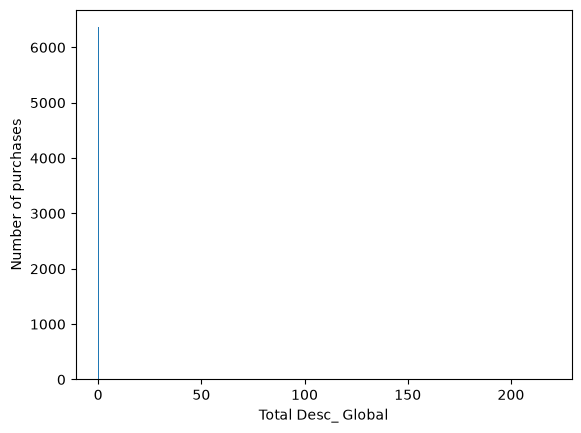

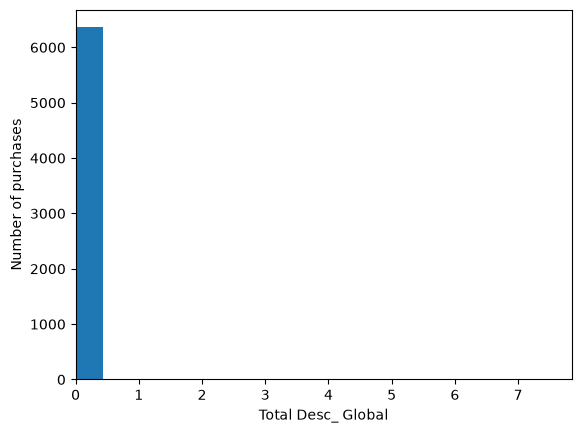

In [339]:
histograms_one_column("Total Desc_ Global", train_raw, 0.99)

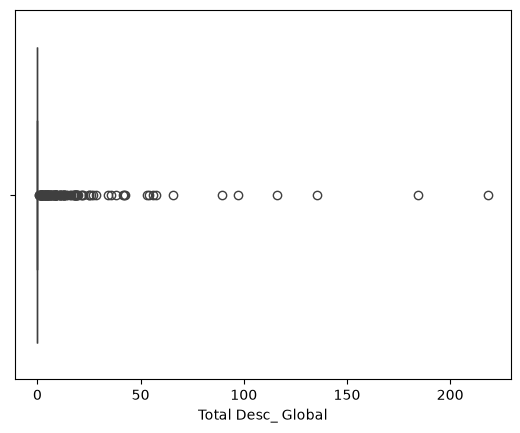

In [340]:
sns.boxplot(x=train_raw["Total Desc_ Global"])

plt.show()

In [342]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 0.35
std = 5.12
minimum = 0.00
q1 = 0.00
q2 = 0.00
q3 = 0.00
maximum = 218.49

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total Desc_ Global"] > upper_bound]
lower_outliers = train_raw[train_raw["Total Desc_ Global"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 0.00
Lower bound: 0.00
Number of upper outliers: 110
Number of lower outliers: 0
Total number of outliers: 110
Percentatge of outliers in our data: 1.68%


Later on we will decide what we do with this field, what we have seen here, is that most of the purchases are with 0 total Desc_ Global, being every value that is no 0 an outlier

### Total Desc_ Linha

In [366]:
descrive_missing("Total Desc_ Linha", train_raw)

Total Desc_ Linha describe:
count    6469.00
mean      112.47
std       289.99
min         0.00
25%         0.00
50%        13.13
75%        92.28
max      4103.44
Name: Total Desc_ Linha, dtype: float64

column_name missings:
65

Total Desc_ Linha top 10 maximum:
          customer_id  Total Desc_ Linha
ID                                      
10001172       531725            4103.44
10003996       807493            3794.51
10002107       400536            3720.00
10004460       770941            3704.89
10004243       781977            3622.51
10001077       227020            3450.47
10002779       531725            3434.18
10006514       849644            3386.82
10002580       531725            3235.74
10002416       531725            3193.40

The top 10 represent the: 4.90% of the whole train data


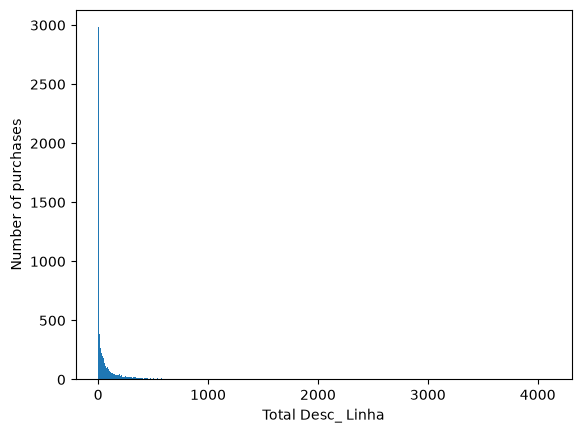

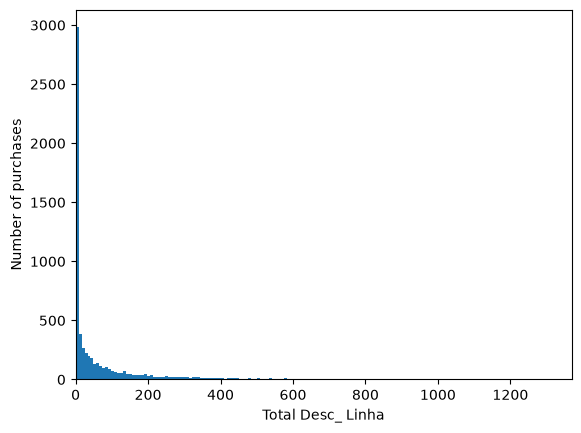

In [345]:
histograms_one_column("Total Desc_ Linha", train_raw, 0.99)

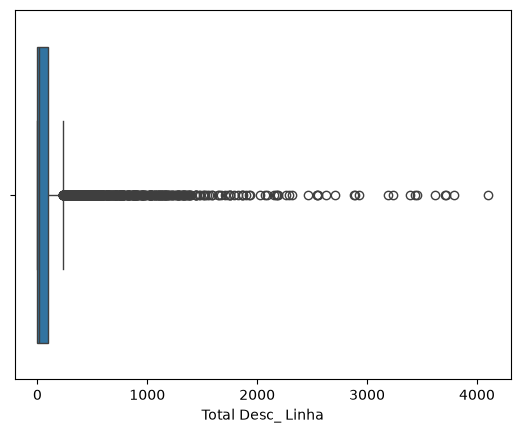

In [347]:
sns.boxplot(x=train_raw["Total Desc_ Linha"])

plt.show()

In [348]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 112.47
std = 289.99
minimum = 0.00
q1 = 0.00
q2 = 13.13
q3 = 92.28
maximum = 4103.44

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Total Desc_ Linha"] > upper_bound]
lower_outliers = train_raw[train_raw["Total Desc_ Linha"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 230.70
Lower bound: -138.42
Number of upper outliers: 822
Number of lower outliers: 0
Total number of outliers: 822
Percentatge of outliers in our data: 12.58%


### N_ Detalhes

In [367]:
descrive_missing("N_ Detalhes", train_raw)

N_ Detalhes describe:
count    6469.00
mean       21.52
std        27.71
min         1.00
25%         4.00
50%        11.00
75%        29.00
max       423.00
Name: N_ Detalhes, dtype: float64

column_name missings:
65

N_ Detalhes top 10 maximum:
          customer_id  N_ Detalhes
ID                                
10006855       488020        423.0
10002061       488020        309.0
10001077       227020        268.0
10003996       807493        243.0
10002202       229396        233.0
10005415       755628        221.0
10003479       227020        199.0
10003698       488020        199.0
10005016       807493        198.0
10007219       508217        197.0

The top 10 represent the: 1.79% of the whole train data


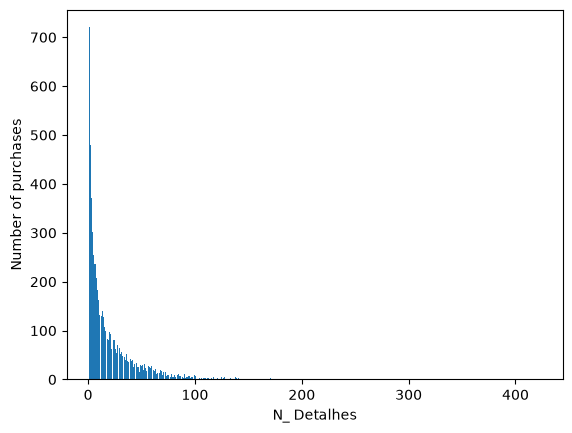

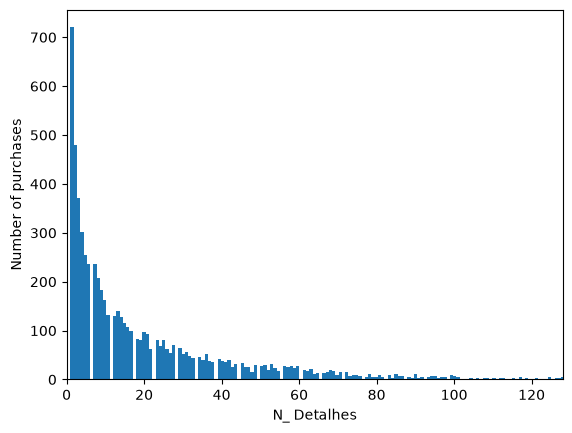

In [350]:
histograms_one_column("N_ Detalhes", train_raw, 0.99)

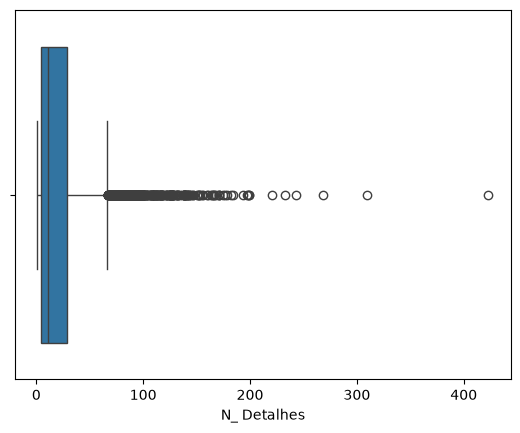

In [351]:
sns.boxplot(x=train_raw["N_ Detalhes"])

plt.show()

In [352]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 21.52
std = 27.71
minimum = 1.00
q1 = 4.00
q2 = 11.00
q3 = 29.00
maximum = 423.00

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["N_ Detalhes"] > upper_bound]
lower_outliers = train_raw[train_raw["N_ Detalhes"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 66.50
Lower bound: -33.50
Number of upper outliers: 436
Number of lower outliers: 0
Total number of outliers: 436
Percentatge of outliers in our data: 6.67%


### Custo

In [368]:
descrive_missing("Custo", train_raw)

Custo describe:
count    6469.00
mean      328.17
std       519.51
min         0.00
25%        49.05
50%       152.54
75%       396.06
max      7427.40
Name: Custo, dtype: float64

column_name missings:
65

Custo top 10 maximum:
          customer_id        Custo
ID                                
10005415       755628  7427.400583
10001077       227020  7052.209816
10006444       864223  6972.197732
10004243       781977  6897.230661
10005853       942149  6111.300000
10003479       227020  5368.567443
10004681       942149  5305.200000
10005875       864223  4924.760864
10001024       781977  4854.694749
10003225       755628  4756.185354

The top 10 represent the: 2.81% of the whole train data


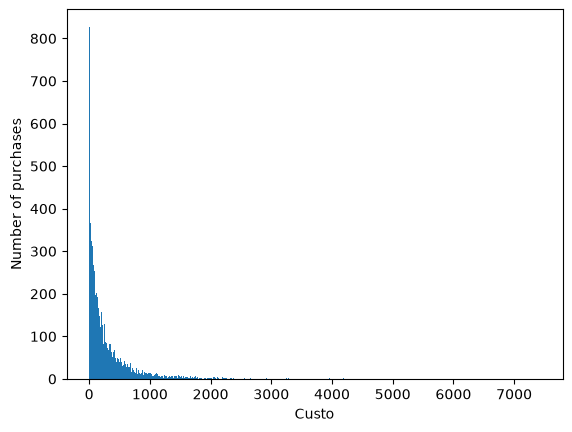

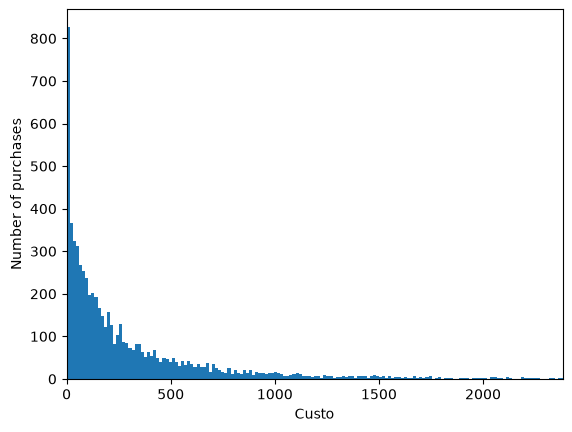

In [369]:
histograms_one_column("Custo", train_raw, 0.99)

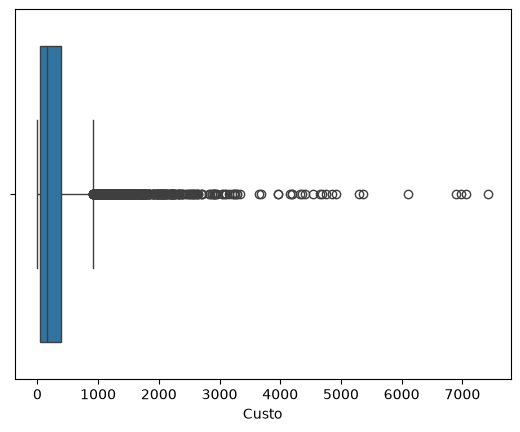

In [370]:
sns.boxplot(x=train_raw["Custo"])

plt.show()

In [372]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 328.17
std = 519.51
minimum = 0.00
q1 = 49.05
q2 = 152.54
q3 = 396.06
maximum = 427.40

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["Custo"] > upper_bound]
lower_outliers = train_raw[train_raw["Custo"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 916.58
Lower bound: -471.46
Number of upper outliers: 539
Number of lower outliers: 0
Total number of outliers: 539
Percentatge of outliers in our data: 8.25%


### prior_total_spend

In [373]:
descrive_missing("prior_total_spend", train_raw)

prior_total_spend describe:
count      6469.00
mean      18908.35
std       31130.87
min           0.00
25%        1505.55
50%        6754.31
75%       21642.32
max      247865.10
Name: prior_total_spend, dtype: float64

column_name missings:
65

prior_total_spend top 10 maximum:
          customer_id  prior_total_spend
ID                                      
10006088       227020          247865.10
10004615       227020          247855.26
10007284       227020          243617.08
10001496       227020          235767.16
10005583       942149          230354.06
10003976       942149          227088.13
10001620       942149          223060.81
10002427       942149          220769.51
10003479       227020          217620.38
10000259       227020          216669.81

The top 10 represent the: 1.89% of the whole train data


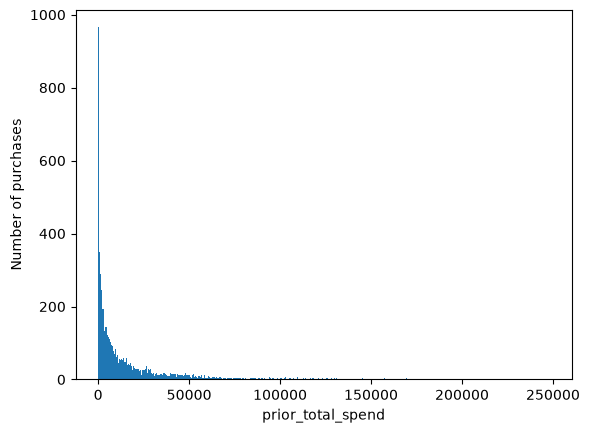

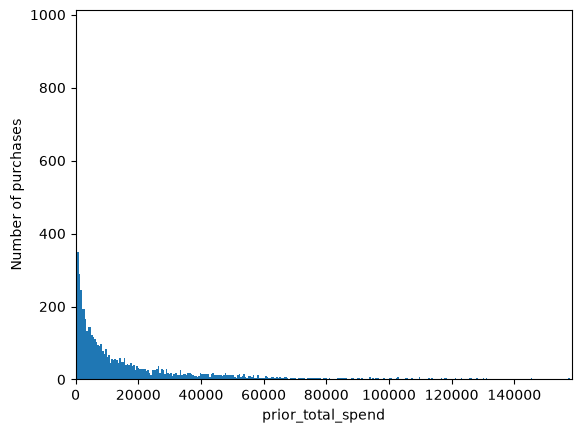

In [374]:
histograms_one_column("prior_total_spend", train_raw, 0.99)

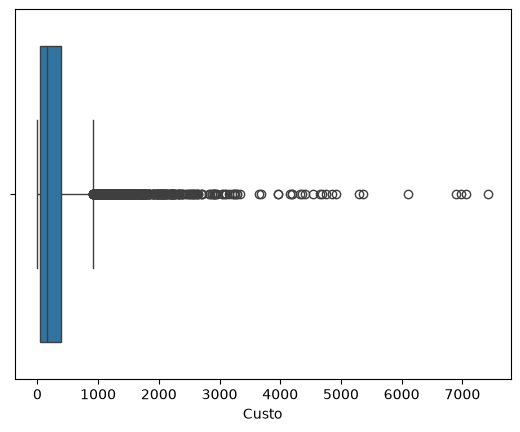

In [375]:
sns.boxplot(x=train_raw["Custo"])

plt.show()

In [376]:
# Previous info from the describe, but let's quantify it:

count = 6469.00
mean = 18908.35
std = 31130.87
minimum = 0.00
q1 = 1505.55
q2 = 6754.31
q3 = 21642.32
maximum = 247865.10


iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
# because we don't have any negative value (smallest total bruto is 0,83) the lower whisker will be in that position
lower_bound = q1 - 1.5 * iqr

upper_outliers = train_raw[train_raw["prior_total_spend"] > upper_bound]
lower_outliers = train_raw[train_raw["prior_total_spend"] < lower_bound]

print(f"Upper bound: {upper_bound:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Number of upper outliers: {len(upper_outliers)}")
print(f"Number of lower outliers: {len(lower_outliers)}")
print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
print(f"Percentatge of outliers in our data: {(len(upper_outliers)/len(train_raw) * 100):.2f}%")


Upper bound: 51847.47
Lower bound: -28699.60
Number of upper outliers: 642
Number of lower outliers: 0
Total number of outliers: 642
Percentatge of outliers in our data: 9.83%


In [417]:
list_of_columns = ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes", "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes", "prior_total_spend"]


comparission_of_top10(list_of_columns, train_raw)


Column Total a Pagar have the following top10 in common with:
     Column Total Bruto: 5
     Column Total Liquido: 8
     Column Total Imp_: 9
     Column Total Portes: 0
     Column Total Desc_ Global: 0
     Column Total Desc_ Linha: 2
     Column Custo: 6
     Column N_ Detalhes: 3
     Column prior_total_spend: 1

Column Total Bruto have the following top10 in common with:
     Column Total a Pagar: 5
     Column Total Liquido: 6
     Column Total Imp_: 5
     Column Total Portes: 1
     Column Total Desc_ Global: 0
     Column Total Desc_ Linha: 6
     Column Custo: 4
     Column N_ Detalhes: 5
     Column prior_total_spend: 1

Column Total Liquido have the following top10 in common with:
     Column Total a Pagar: 8
     Column Total Bruto: 6
     Column Total Imp_: 7
     Column Total Portes: 0
     Column Total Desc_ Global: 0
     Column Total Desc_ Linha: 2
     Column Custo: 4
     Column N_ Detalhes: 5
     Column prior_total_spend: 1

Column Total Imp_ have the following

In [ ]:


invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase        16
customer_tenure_days                 0
prior_purchase_count                 0
prior_mean_purchase_value           16
prior_std_purchase_value             0
prior_min_purchase_value             0
prior_max_purchase_value             0
prior_mean_gap_days                 16
prior_std_gap_days                   0
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d                  0
spend_180d                           0
purchase_count_365d                  0
spend_365d                          15
random_noise                      3357

In [273]:
| column | what it holds | role |
|---|---|---|
| `repeat_purchase_90d` | Target: 1 if the customer purchases again within 90 days; 0 otherwise. Train only. | **target** |
| `ID` | Unique modelling-row and Kaggle submission identifier | row identifier |
| `customer_id` | Anonymized customer identifier; join key for clientes.csv | row identifier to join with clientes.csv |
| `purchase_date` | Anonymized purchase date. Temporal order and intervals are preserved. | Datetime |
| `Total a Pagar` | Current transaction totals, tax, shipping, discounts and cost | Numerical countinuous |
| `year` | registration year | numeric, but a year rather than a quantity |
| `mileage` | distance covered | numeric |
| `tax` | annual road tax in EUR | numeric |
| `mpg` | miles per gallon, the maker's figure | numeric |
| `engineSize` | displacement in litres | numeric |
| `paintQuality%` | condition of the paintwork, 0 to 100 | numeric |
| `previousOwners` | how many owners before this sale | numeric count |

SyntaxError: unterminated string literal (detected at line 11) (1641203975.py, line 11)